cuda


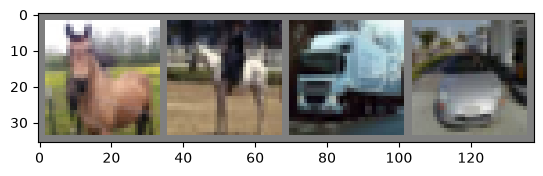

horse horse truck automobile
[1,  2000] loss: 2.203
[1,  4000] loss: 1.883
[1,  6000] loss: 1.680
[1,  8000] loss: 1.588
[1, 10000] loss: 1.539
[1, 12000] loss: 1.470
[2,  2000] loss: 1.400
[2,  4000] loss: 1.375
[2,  6000] loss: 1.345
[2,  8000] loss: 1.318
[2, 10000] loss: 1.316
[2, 12000] loss: 1.288
Finished Training


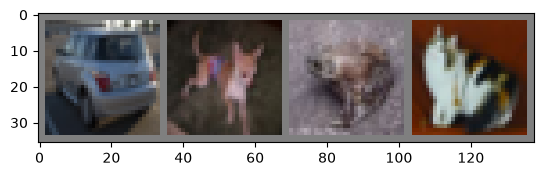

GroundTruth:  automobile dog   frog  cat  
----------------------------------------
Predicted:  automobile horse deer  dog  


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            (
                0.5,
                0.5,
                0.5
            ),
            (
                0.5,
                0.5,
                0.5
            )
        ),
    ]
)


batch_size = 4

trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=True, num_workers=2)


def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(trainloader)
images, labels = next(dataiter)

classes = trainset.classes

imshow(torchvision.utils.make_grid(images))
print(" ".join(f"{classes[labels[j]]:5s}" for j in range(batch_size)))


class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)  # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        x = self.fc3(x)
        return x


net = Net().to(device)

criterion = nn.CrossEntropyLoss()  # CEL을 쓴다면 classification
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

num_epochs = 2
for epoch in range(num_epochs):
    
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 2000 == 1999:  # print every 2000 mini-batches
            print(f"[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}")
            running_loss = 0.0


print("Finished Training")


PATH = "./cifar_net.pth"
torch.save(net.state_dict(), PATH)

dataiter = iter(testloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print("GroundTruth: ", " ".join(f"{classes[label.item()]:5s}" for label in labels))


print("-" * 40)
net.load_state_dict(torch.load(PATH, map_location=device))
net.eval()


with torch.inference_mode():
    outputs = net(images.to(device))
    predicted = outputs.argmax(dim=1).cpu()
print("Predicted: ", " ".join(f"{classes[p.item()]:5s}" for p in predicted))
